In [31]:
import pandas as pd
import numpy as np

df = pd.read_csv('medical_insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
2767,47,female,45.320,1,no,southeast,8569.86180
2768,21,female,34.600,0,no,southwest,2020.17700
2769,19,male,26.030,1,yes,northwest,16450.89470
2770,23,male,18.715,0,no,northwest,21595.38229


In [24]:
# Performing First Look Ritual

df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   object 
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   object 
 5   region    2772 non-null   object 
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 151.7+ KB


,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


In [25]:
# Checking Data types

df.dtypes

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


In [26]:
# Checking Missing Columns

count = df.isnull().sum()
print(count)

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


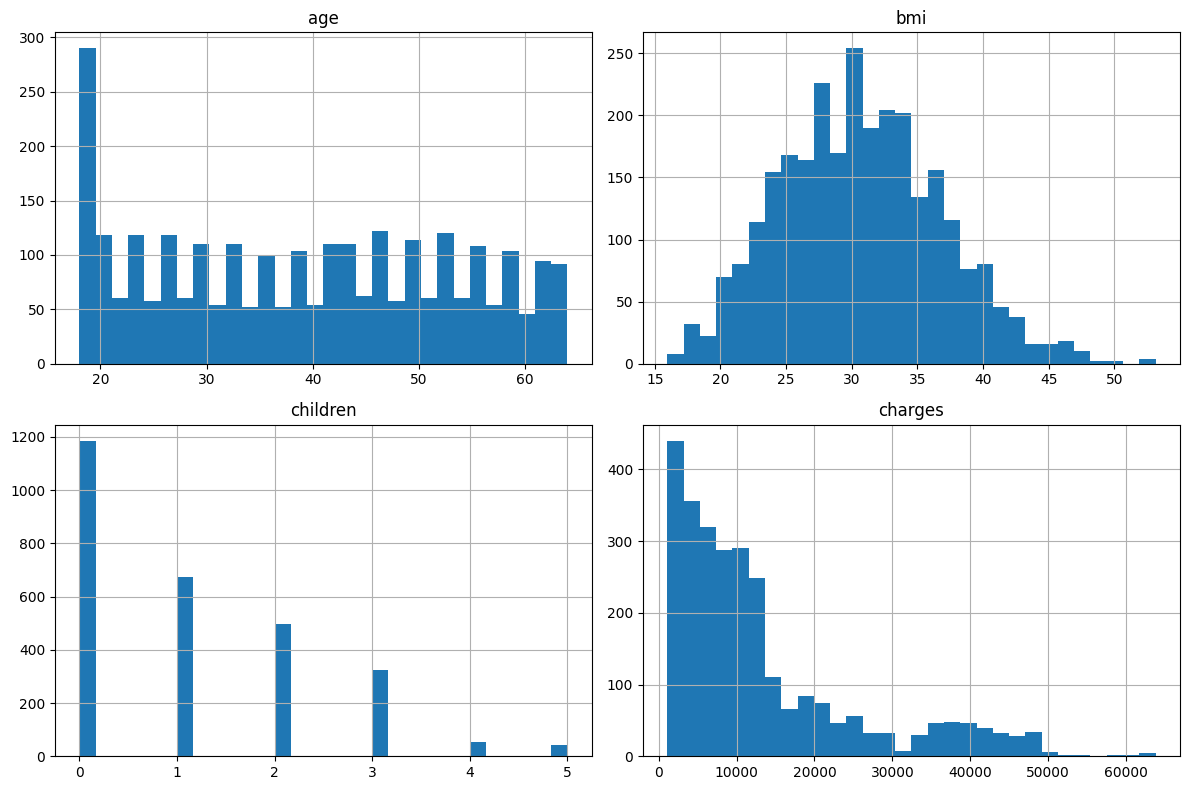

In [27]:
# Visual EDA: Histogram

import matplotlib.pyplot as plt

df.hist(figsize=(12,8), bins=30)
plt.tight_layout()
plt.show()

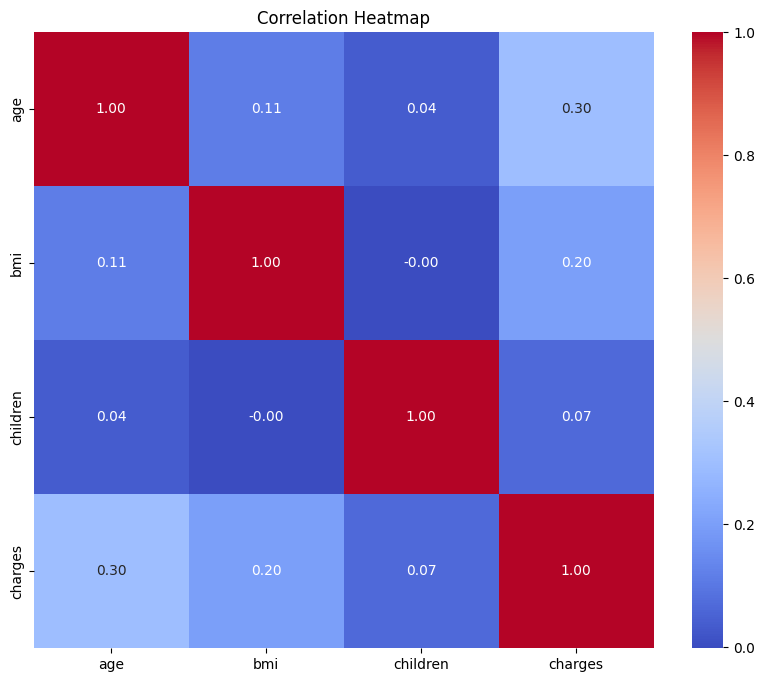

In [28]:
# Visual EDA: Heatmap

import seaborn as sns

corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
# Visual EDA: Scatter Plot


In [32]:
# Encoding Text Values

df = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)
df

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...
2767,47,45.320,1,8569.86180,False,False,False,True,False
2768,21,34.600,0,2020.17700,False,False,False,False,True
2769,19,26.030,1,16450.89470,True,True,True,False,False
2770,23,18.715,0,21595.38229,True,False,True,False,False


In [12]:
# Scaling

from sklearn.preprocessing import StandardScaler

x = df.drop(columns=['charges'])
y = df['charges']
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

print(x_scaled)

[[-1.42835311 -0.45711365 -0.9070836  ... -0.56124016 -0.61794372
   1.74717818]
 [-1.49938129  0.50073091 -0.08375821 ... -0.56124016  1.61827036
  -0.57235147]
 [-0.7890995   0.37508521  1.56289256 ... -0.56124016  1.61827036
  -0.57235147]
 ...
 [-1.42835311 -0.76225322 -0.08375821 ...  1.78176845 -0.61794372
  -0.57235147]
 [-1.14424039 -1.95588746 -0.9070836  ...  1.78176845 -0.61794372
  -0.57235147]
 [ 1.05763316  0.14663846 -0.9070836  ... -0.56124016 -0.61794372
   1.74717818]]


In [13]:
# Train/Test Split

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.2, random_state=42)

print(f'Training Rows: {len(x_train)}')
print(f'Testing Rows: {len(x_test)}')

Training Rows: 2217
Testing Rows: 555


In [14]:
# Linear Regression: Predicting

from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(x_train, y_train)
lin.preds = lin.predict(x_test)

In [15]:
# Linear Regression: Metrics

from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error, r2_score

print(f'Linear Regression Metrics:-')
print(f'MSE: {mean_squared_error(y_test, lin.preds)}')
print(f'MAE: {mean_absolute_error(y_test, lin.preds)}')
print(f'RMSE: {root_mean_squared_error(y_test, lin.preds)}')
print(f'R2: {r2_score(y_test, lin.preds)}')

Linear Regression Metrics:-
MSE: 39933194.54805148
MAE: 4160.24797476299
RMSE: 6319.27167860755
R2: 0.73981661775643


In [17]:
# Random Forest: Predicting

from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(n_estimators=100, random_state=42)
forest.fit(x_train, y_train)
forest.preds = forest.predict(x_test)

In [18]:
# Random Forest: Metrics

print(f'Random Forest Metrics:-')
print(f'MSE: {mean_squared_error(y_test, forest.preds)}')
print(f'MAE: {mean_absolute_error(y_test, forest.preds)}')
print(f'RMSE: {root_mean_squared_error(y_test, forest.preds)}')
print(f'R2: {r2_score(y_test, forest.preds)}')

Random Forest Metrics:-
MSE: 7565920.46803508
MAE: 1272.556768795604
RMSE: 2750.621832974333
R2: 0.9507045003677204


In [20]:
importances = pd.Series(forest.feature_importances_, index=x.columns)
importances = importances.sort_values(ascending=False)
print('Importances:-')
print(importances)

Importances:-
smoker_yes          0.629522
bmi                 0.208609
age                 0.124689
children            0.016624
sex_male            0.005723
region_northwest    0.005685
region_southeast    0.004962
region_southwest    0.004185
dtype: float64


In [22]:
# Winning model

print(f'Winning Model: Random Forest')
print(f'Top Feature: smoker_yes ')

Winning Model: Random Forest
Top Feature: smoker_yes 
